# Segmentação de pluma de fumaça com SAM

In [1]:
!pip install ultralytics -q

     ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 46.9/46.9 kB 2.1 MB/s eta 0:00:00
   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 1.4/1.4 MB 84.7 MB/s eta 0:00:00
   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 97.6/97.6 kB 10.9 MB/s eta 0:00:00


Creating new Ultralytics Settings v0.0.8 file ✅ 
View Ultralytics Settings with 'yolo settings' or at '/root/.config/Ultralytics/settings.json'
Update Settings with 'yolo settings key=value', i.e. 'yolo settings runs_dir=path/to/dir'. For help see https://docs.ultralytics.com/usage/settings.


Saving WhatsApp Image 2026-09-21 at 21.22.40.jpeg to WhatsApp Image 2026-09-21 at 21.22.40.jpeg
1200 1600


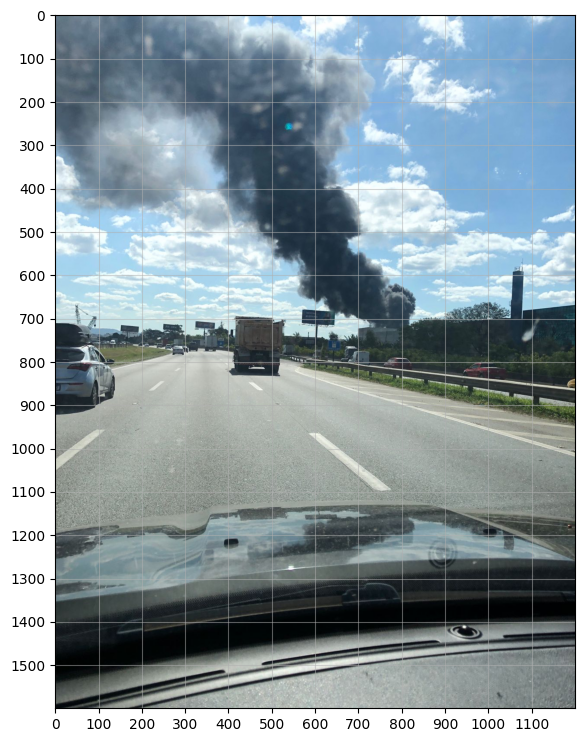

In [2]:
import os
import cv2
import numpy as np
import matplotlib.pyplot as plt
from scipy import ndimage as ndi
from ultralytics import SAM

caminho = "pluma.jpeg"
if not os.path.exists(caminho):
    from google.colab import files
    enviado = files.upload()
    caminho = list(enviado.keys())[0]

img_bgr = cv2.imread(caminho)
img = cv2.cvtColor(img_bgr, cv2.COLOR_BGR2RGB)
H, W = img.shape[:2]
print(W, H)

plt.figure(figsize=(7, 9))
plt.imshow(img)
plt.xticks(range(0, W, 100))
plt.yticks(range(0, H, 100))
plt.grid(alpha=.5)
plt.show()

In [3]:
model = SAM("sam2.1_b.pt")

def segmentar(imagem, caixa=None, pos=(), neg=()):
    args = {}
    pontos = [list(p) for p in pos] + [list(p) for p in neg]
    rotulos = [1] * len(pos) + [0] * len(neg)
    if pontos:
        args["points"] = [pontos]
        args["labels"] = [rotulos]
    if caixa is not None:
        args["bboxes"] = [list(caixa)]
    r = model(imagem, verbose=False, **args)[0]
    h, w = imagem.shape[:2]
    if r.masks is None:
        return np.zeros((h, w), bool), 0.0
    m = r.masks.data[0].cpu().numpy() > 0.5
    if m.shape != (h, w):
        m = cv2.resize(m.astype(np.uint8), (w, h), interpolation=cv2.INTER_NEAREST).astype(bool)
    return m, float(r.boxes.conf[0])

def sobrepor(imagem, m):
    s = imagem.copy()
    s[m] = (0.5 * s[m] + 0.5 * np.array([255, 40, 40])).astype(np.uint8)
    cont, _ = cv2.findContours(m.astype(np.uint8), cv2.RETR_EXTERNAL, cv2.CHAIN_APPROX_NONE)
    cv2.drawContours(s, cont, -1, (255, 255, 0), 3)
    return s

def prompts(ax, cfg):
    if cfg.get("caixa") is not None:
        x1, y1, x2, y2 = cfg["caixa"]
        ax.add_patch(plt.Rectangle((x1, y1), x2 - x1, y2 - y1, fill=False, ec="cyan", lw=2))
    for x, y in cfg.get("pos", ()):
        ax.plot(x, y, "*", ms=14, mfc="lime", mec="black")
    for x, y in cfg.get("neg", ()):
        ax.plot(x, y, "X", ms=12, mfc="red", mec="white")

def comparar(resultados, arquivo=None, corte=800):
    fig, eixos = plt.subplots(len(resultados), 3, figsize=(15, 5 * len(resultados)))
    for linha, (nome, r) in zip(np.atleast_2d(eixos), resultados.items()):
        linha[0].imshow(img)
        prompts(linha[0], r["cfg"])
        linha[0].set_title(nome + " - original")
        linha[1].imshow(r["mask"], cmap="gray")
        linha[1].set_title("máscara binária")
        linha[2].imshow(sobrepor(img, r["mask"]))
        linha[2].set_title(f"sobreposição (score {r['score']:.2f})")
        for a in linha:
            a.set_ylim(corte, 0)
            a.set_xlim(0, W)
            a.axis("off")
    plt.tight_layout()
    if arquivo:
        plt.savefig(arquivo, dpi=120, bbox_inches="tight")
    plt.show()

## Teste com três configurações de prompt

1. um ponto positivo dentro da pluma
2. caixa delimitadora em volta da pluma
3. caixa com pontos positivos na pluma e pontos negativos no céu, nas nuvens e nas árvores

1. ponto positivo 0.928 15.8% da imagem
2. caixa 0.923 17.0% da imagem
3. caixa + pontos 0.724 14.2% da imagem


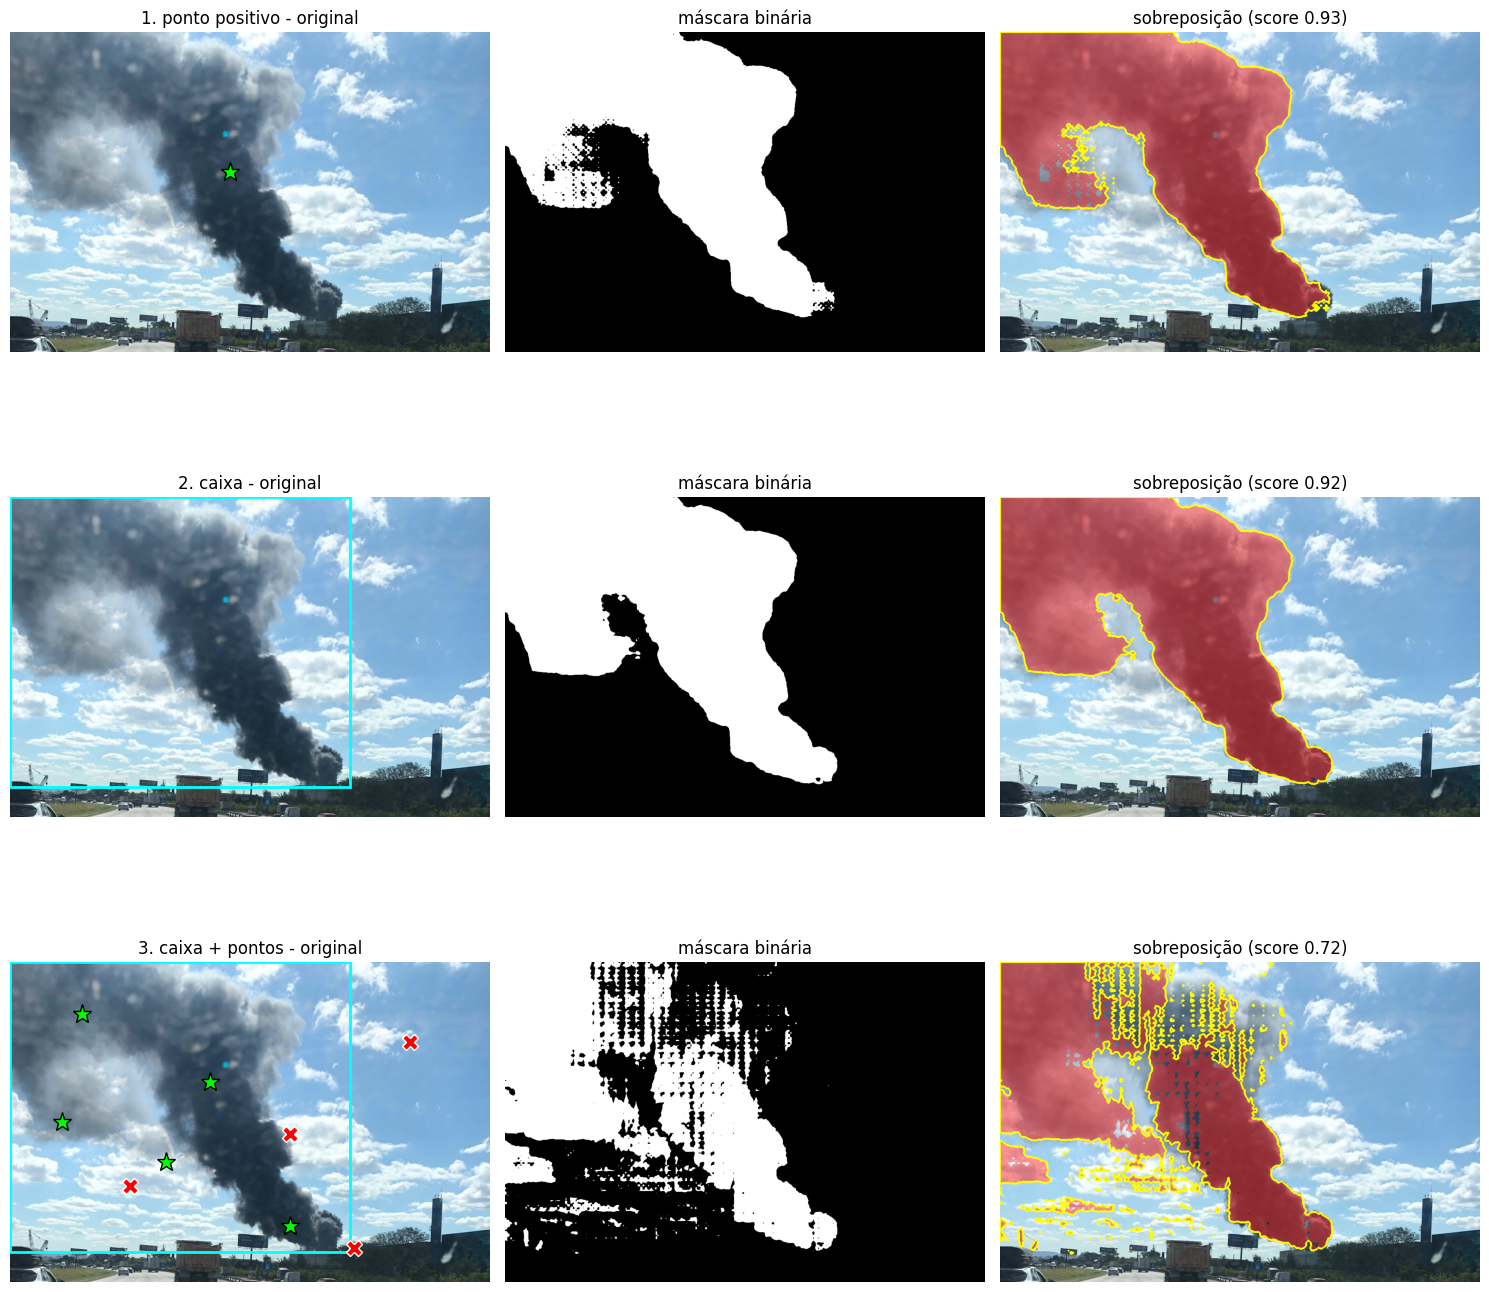

In [4]:
caixa = [0, 0, 850, 725]

configs = {
    "1. ponto positivo": dict(pos=[(550, 350)]),
    "2. caixa": dict(caixa=caixa),
    "3. caixa + pontos": dict(
        caixa=caixa,
        pos=[(500, 300), (180, 130), (130, 400), (390, 500), (700, 660)],
        neg=[(1000, 200), (700, 430), (300, 560), (860, 715)],
    ),
}

resultados = {}
for nome, cfg in configs.items():
    m, s = segmentar(img_bgr, **cfg)
    resultados[nome] = dict(mask=m, score=s, cfg=cfg)
    print(nome, round(s, 3), f"{100 * m.mean():.1f}% da imagem")

comparar(resultados, "comparacao_prompts.png")

## Melhorando a máscara

O SAM 2 reduz a imagem para 1024x1024 antes de segmentar, então rodei o modelo só no recorte em volta da pluma e depois fechei buracos e removi pedaços pequenos da máscara.

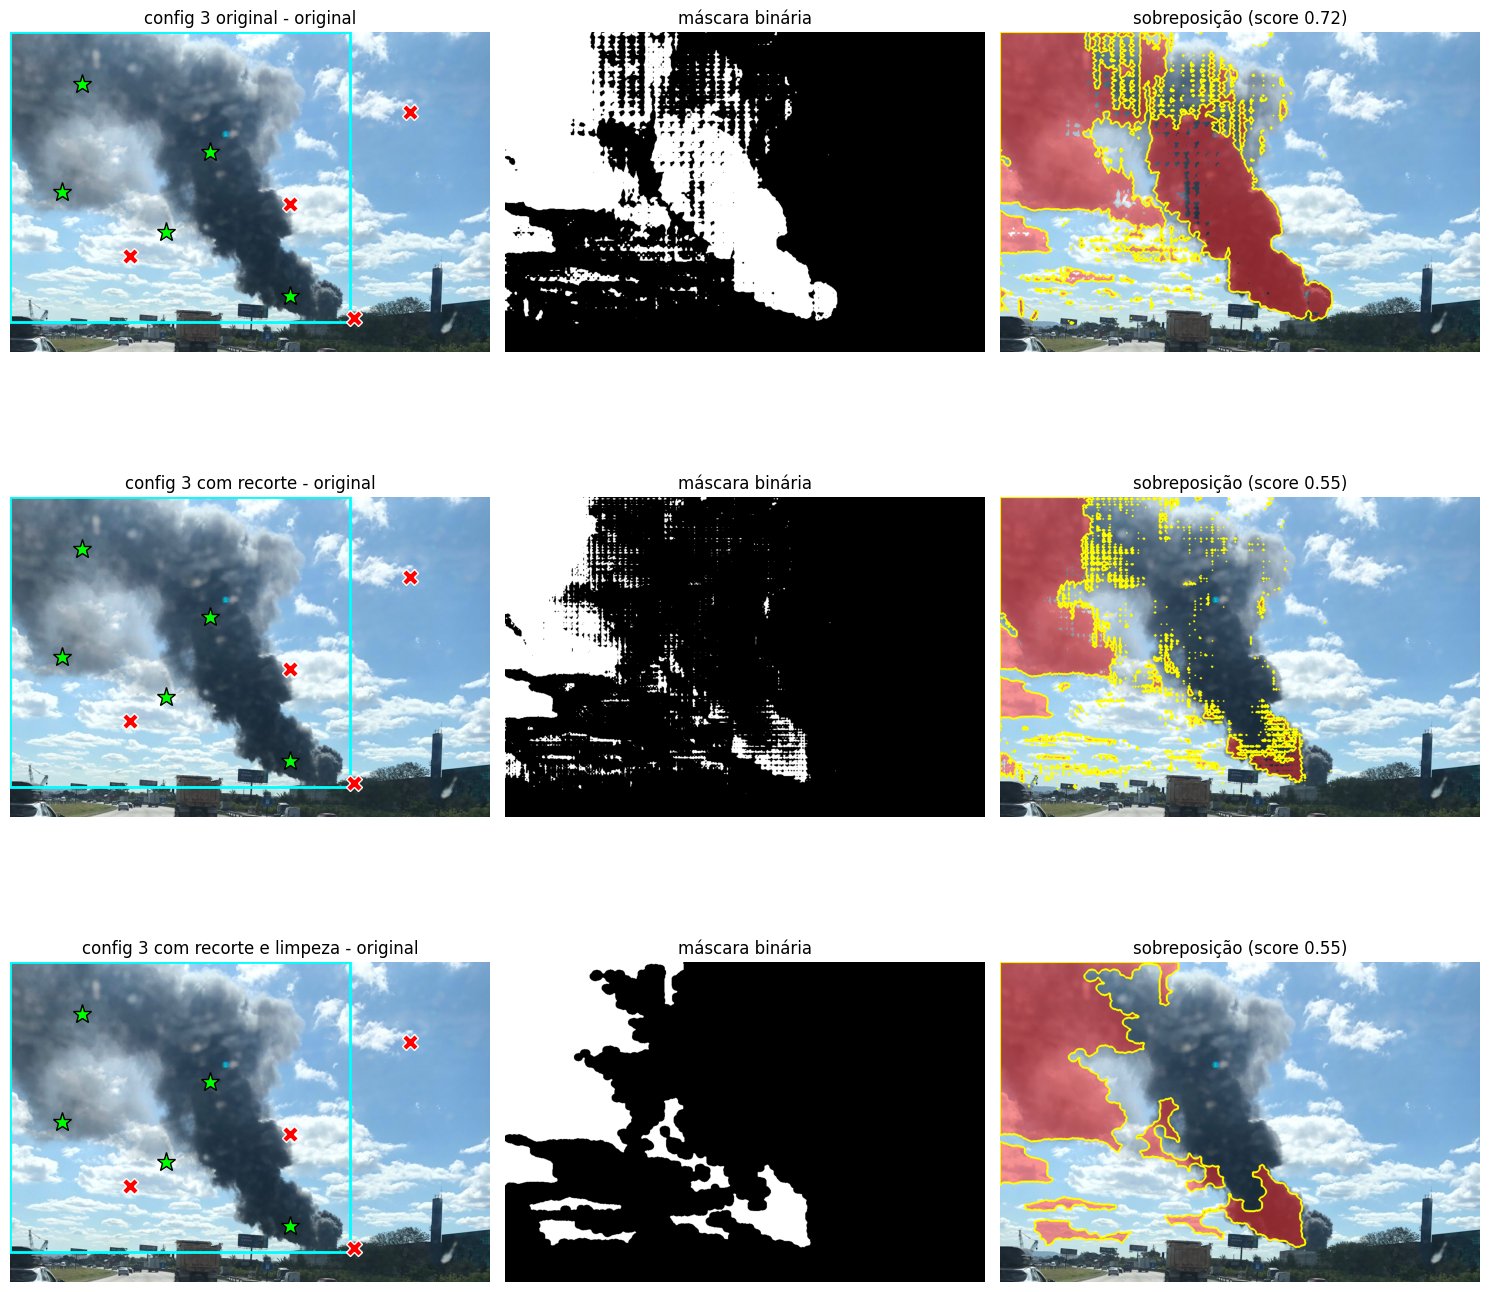

In [5]:
def segmentar_recorte(imagem, caixa, pos=(), neg=(), margem=60):
    h, w = imagem.shape[:2]
    x1, y1, x2, y2 = caixa
    X0, Y0 = max(0, x1 - margem), max(0, y1 - margem)
    X1, Y1 = min(w, x2 + margem), min(h, y2 + margem)
    desloc = lambda L: [(x - X0, y - Y0) for x, y in L if X0 <= x < X1 and Y0 <= y < Y1]
    m, s = segmentar(imagem[Y0:Y1, X0:X1], caixa=(x1 - X0, y1 - Y0, x2 - X0, y2 - Y0),
                     pos=desloc(pos), neg=desloc(neg))
    total = np.zeros((h, w), bool)
    total[Y0:Y1, X0:X1] = m
    return total, s

def limpar(m, fechar=21, abrir=5, minimo=0.002):
    m = m.astype(np.uint8)
    m = cv2.morphologyEx(m, cv2.MORPH_CLOSE, cv2.getStructuringElement(cv2.MORPH_ELLIPSE, (fechar, fechar)))
    m = cv2.morphologyEx(m, cv2.MORPH_OPEN, cv2.getStructuringElement(cv2.MORPH_ELLIPSE, (abrir, abrir)))
    m = ndi.binary_fill_holes(m).astype(np.uint8)
    n, rot, est, _ = cv2.connectedComponentsWithStats(m, connectivity=8)
    saida = np.zeros_like(m)
    for i in range(1, n):
        if est[i, cv2.CC_STAT_AREA] >= minimo * m.size:
            saida[rot == i] = 1
    return saida.astype(bool)

cfg = configs["3. caixa + pontos"]
m_recorte, s_recorte = segmentar_recorte(img_bgr, **cfg)
m_final = limpar(m_recorte)

melhorias = {
    "config 3 original": resultados["3. caixa + pontos"],
    "config 3 com recorte": dict(mask=m_recorte, score=s_recorte, cfg=cfg),
    "config 3 com recorte e limpeza": dict(mask=m_final, score=s_recorte, cfg=cfg),
}
comparar(melhorias, "comparacao_melhorias.png")

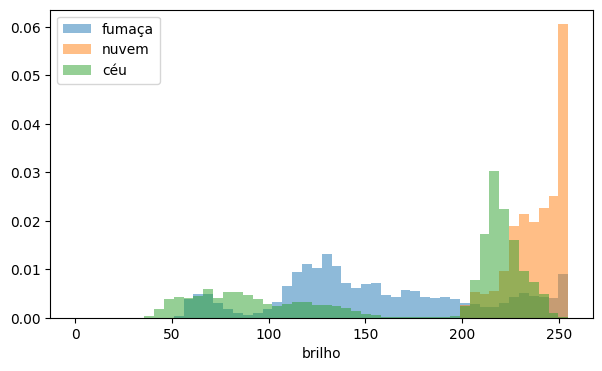

brilho mediano: 146.0 242.0 213.0
fumaça com brilho de nuvem: 19.6 %


In [6]:
cv2.imwrite("mascara_final.png", m_final.astype(np.uint8) * 255)
cv2.imwrite("sobreposicao_final.png", cv2.cvtColor(sobrepor(img, m_final), cv2.COLOR_RGB2BGR))

hsv = cv2.cvtColor(img, cv2.COLOR_RGB2HSV)
S, V = hsv[..., 1], hsv[..., 2]
nuvem = (V > 200) & (S < 45) & ~m_final
nuvem[800:] = False
ceu = (hsv[..., 0] >= 95) & (hsv[..., 0] <= 130) & (S > 70) & ~m_final
ceu[800:] = False

plt.figure(figsize=(7, 4))
plt.hist(V[m_final], bins=50, range=(0, 255), alpha=.5, density=True, label="fumaça")
plt.hist(V[nuvem], bins=50, range=(0, 255), alpha=.5, density=True, label="nuvem")
plt.hist(V[ceu], bins=50, range=(0, 255), alpha=.5, density=True, label="céu")
plt.xlabel("brilho")
plt.legend()
plt.show()

print("brilho mediano:", np.median(V[m_final]), np.median(V[nuvem]), np.median(V[ceu]))
print("fumaça com brilho de nuvem:", round(100 * (V[m_final] >= np.percentile(V[nuvem], 5)).mean(), 1), "%")

## Análise

**- A máscara cobre a pluma?** Com um ponto só, a máscara pegou a coluna central e a massa escura do topo (score 0,93).

**- Inclui regiões que não são da pluma?** Quase nada de céu ou nuvem, mas na base a máscara avança um pouco sobre as árvores.

**- Deixa partes de fora?** Sim. O lobo da esquerda, onde a fumaça está clara por causa do sol, ficou com um buraco irregular. A pluma também é cortada pelo topo e pela lateral da foto, então a máscara encosta nas bordas.

**- Comparando os prompts:**
1. Um ponto positivo (score 0,93). A máscara pega bem a coluna central e a massa escura do topo, mas o lobo esquerdo, onde a fumaça está clara, fica fragmentado e pontilhado. Não há céu nem nuvem dentro da máscara.

2. Só a caixa (score 0,92). Foi o melhor resultado: a máscara ficou sólida e com contorno limpo, incluiu o lobo esquerdo quase inteiro e não avançou sobre a vegetação da base. A caixa deu ao modelo o contexto de onde está a pluma.

3. Caixa + pontos positivos e negativos (score 0,72). Foi o pior: a máscara ficou toda picotada, com listras verticais, buracos na coluna e manchas de nuvem baixa incluídas no canto inferior esquerdo.

**- O que dificultou:**
- Contraluz: o núcleo da fumaça é quase preto e as partes iluminadas são cinza-claras, então a mesma pluma tem duas aparências.
- Contraste: contra o céu azul o núcleo se destaca, mas nas bordas a fumaça é fina e translúcida e o azul aparece através dela. Na base ela se confunde com as árvores escuras.
- Nuvens: a fumaça clara tem brilho e saturação parecidos com os dos cúmulos ao redor, como mostra o histograma. Só a cor não separa os dois, por isso os pontos negativos nas nuvens ajudam.
- O capô e o reflexo do para-brisa ocupam metade da foto e gastam resolução na entrada do modelo, o que justifica o recorte.